# AI ANALYST LAB

![](../_img/ai_analyst_lab.png)

### A Hands-on Course on AI for Data Analysts
## Review 05: Exponentials and Logarithms

Feedback should be sent to [goran.milovanovic@datakolektiv.com](mailto:goran.milovanovic@datakolektiv.com).

This is a **review notebook**. Two of the course's most important tools — **binomial logistic regression** (Session 05) and **maximum likelihood estimation** (Session 05 and Review 04) — are built on the **exponential** and **logarithmic** functions: the log-odds, the sigmoid curve, odds ratios, the log-likelihood, the deviance. The sessions use them; this review is the pause that explains them.

We build the whole thing **from scratch** — assuming you may not have touched a logarithm since school — but we go **only as far as those two destinations require**. The order is deliberate: **exponentials first**, then **logarithms as their inverse**, then the handful of rules, then exactly how they power logistic regression and likelihood. **No calculus anywhere.**

***
### What we will do today

Seven small steps, each computed and plotted so the ideas are concrete, not abstract.

| Section | Idea | Where it powers the course |
|---|---|---|
| R5.1 | **Exponents** and their rules | the foundation for everything below |
| R5.2 | The **exponential function** and the number $e$ | the sigmoid curve (Session 05) |
| R5.3 | **Logarithms** — the inverse question | the log-odds (Session 05), the log-likelihood (R04) |
| R5.4 | The **rules of logarithms** | *product → sum*, the key to likelihood (R04, Session 05) |
| R5.5 | **Two properties** that do all the later work | why the log-odds scale; why we maximise the *log*-likelihood |
| R5.6 | **Bridge 1** — logs & exp in **logistic regression** | logit, sigmoid, odds ratios (Session 05, §5.5–§5.11) |
| R5.7 | **Bridge 2** — logs in **maximum likelihood** | log-likelihood, deviance (Session 05 §5.8/§5.12, R04) |

Method, as always in these reviews: **compute first, then read the number.**

***
The only tools we need: **NumPy** for the arithmetic and **matplotlib** for the pictures.

In [1]:
import numpy as np
import matplotlib.pyplot as plt

plt.rcParams["figure.figsize"] = (8, 5)
print("Ready.")

Ready.


***
## R5.1 Exponents, from the ground up

Start with the simplest idea. An **exponent** is just **repeated multiplication**: $b^n$ means "multiply $b$ by itself $n$ times." Picture a rumour that **doubles** every hour — after $n$ hours it is $2^n$ times as large. The base $b$ is *what* grows; the exponent $n$ is *how many times*.

$$2^3 = 2 \times 2 \times 2 = 8$$

From that one idea, a few **rules** follow — and they are the rules we will lean on for the rest of the notebook:

- **Product rule:** $b^m \cdot b^n = b^{\,m+n}$  — multiplying means *adding* the exponents. (Three doublings then two more = five doublings.)
- **Quotient rule:** $b^m / b^n = b^{\,m-n}$  — dividing means *subtracting* the exponents.
- **Power rule:** $(b^m)^n = b^{\,m n}$.
- **Zero:** $b^0 = 1$  (no multiplications leaves you at 1).
- **Negative:** $b^{-n} = 1/b^n$  (a negative exponent means *divide* — i.e. halve instead of double).
- **Fractional:** $b^{1/2} = \sqrt{b}$  (a half-power is a root).

The single most important one for later is the **product rule** — *"multiply the numbers, add the exponents."* Hold onto it. Let's confirm the rules are real, not magic:

In [2]:
# Product rule: 2^3 * 2^4 should equal 2^(3+4) = 2^7
print("2^3 * 2^4 =", 2**3 * 2**4, " and  2^7 =", 2**7)

# A few edge cases, to make the rules concrete.
print("2^0      =", 2**0)          # anything to the 0 is 1
print("2^-2     =", 2**-2)         # negative exponent -> divide
print("2^0.5    =", round(2**0.5, 4), " (= sqrt(2))")

2^3 * 2^4 = 128  and  2^7 = 128
2^0      = 1
2^-2     = 0.25
2^0.5    = 1.4142  (= sqrt(2))


***
## R5.2 The exponential function and the number $e$

So far $n$ was a whole number of doublings. But growth does not happen in jumps — money earns interest *continuously*, a population grows *every instant*. So we let the exponent be **any real number** $x$, and $b^x$ becomes a smooth **function**.

One base is so natural for continuous growth that it gets its own letter: **$e \approx 2.71828$**. You do not need its deep definition — just treat $e^x$ (also written $\exp(x)$) as *the* standard growth curve. Three facts are all we need:

- $e^x$ is **always positive** — it never touches zero or goes negative.
- $e^0 = 1$, and it is **strictly increasing** — bigger $x$, bigger $e^x$, always.
- It obeys the product rule in its most useful form: $\;e^{a+b} = e^a \cdot e^b\;$ — **adding in the exponent = multiplying the values.** (This one line is the whole secret behind *odds ratios* in R5.6.)

Let's look at its shape:

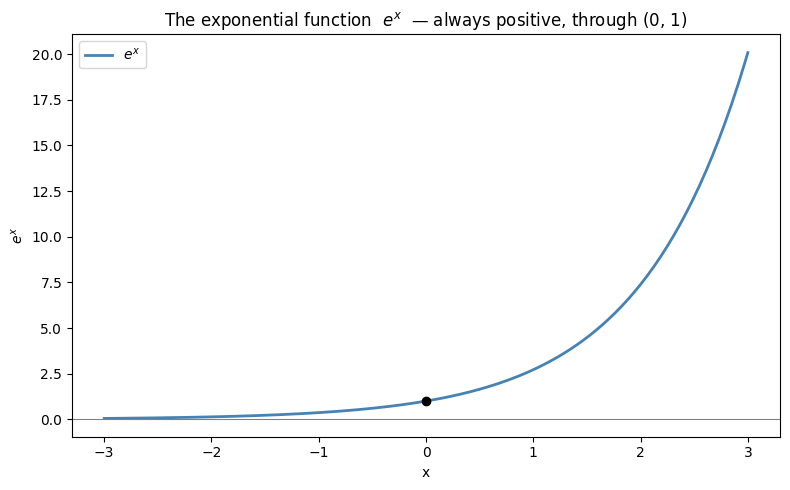

e        = 2.71828
e^0      = 1.0
e^(1+2)  = 20.0855  and  e^1 * e^2 = 20.0855


In [3]:
x = np.linspace(-3, 3, 200)

plt.plot(x, np.exp(x), color="steelblue", lw=2, label=r"$e^x$")
plt.scatter([0], [1], color="black", zorder=5)          # the anchor point (0, 1)
plt.axhline(0, color="grey", lw=0.8)                    # y = 0: the curve never crosses it
plt.title("The exponential function  $e^x$  — always positive, through (0, 1)")
plt.xlabel("x"); plt.ylabel(r"$e^x$")
plt.legend(); plt.tight_layout(); plt.show()

print("e        =", round(np.e, 5))
print("e^0      =", np.exp(0))
print("e^(1+2)  =", round(np.exp(1+2), 4), " and  e^1 * e^2 =", round(np.exp(1)*np.exp(2), 4))

***
## R5.3 Logarithms — the inverse question

A **logarithm** simply asks the question that undoes an exponential: *"to get this number, to what power must I raise the base?"* For example, with base 2:

$$\log_2(8) = 3 \qquad \text{because} \qquad 2^3 = 8.$$

When the base is $e$, we call it the **natural logarithm** and write **$\ln$**. It is the exact inverse of $e^x$:

$$\ln(e^x) = x \qquad\text{and}\qquad e^{\ln y} = y.$$

Two consequences to keep in mind:

- $\ln$ and $e^x$ **undo each other** — this is the fact we will use again and again.
- $\ln$ only accepts **positive** inputs. There is no power you can raise $e$ to that gives 0 or a negative number (remember $e^x$ is always positive), so $\ln(0)$ and $\ln(\text{negative})$ are undefined.

Because they are inverses, their graphs are **mirror images** across the line $y = x$:

ln(e^2.5)  = 2.5
e^(ln 4)   = 4.0


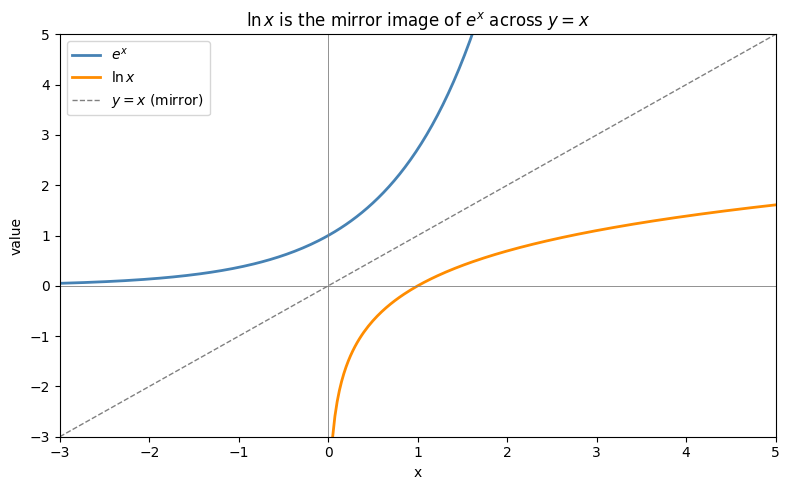

In [4]:
# Inverses undo each other -- check numerically first.
print("ln(e^2.5)  =", round(np.log(np.exp(2.5)), 4))
print("e^(ln 4)   =", round(np.exp(np.log(4)), 4))

# Now the mirror-image picture.
x  = np.linspace(-3, 3, 200)
xp = np.linspace(0.05, 5, 200)        # ln only takes positive inputs

plt.plot(x,  np.exp(x), color="steelblue", lw=2, label=r"$e^x$")
plt.plot(xp, np.log(xp), color="darkorange", lw=2, label=r"$\ln x$")
plt.plot([-3, 5], [-3, 5], color="grey", ls="--", lw=1, label=r"$y = x$ (mirror)")
plt.axhline(0, color="grey", lw=0.6); plt.axvline(0, color="grey", lw=0.6)
plt.xlim(-3, 5); plt.ylim(-3, 5)
plt.title(r"$\ln x$ is the mirror image of $e^x$ across $y = x$")
plt.xlabel("x"); plt.ylabel("value")
plt.legend(); plt.tight_layout(); plt.show()

***
## R5.4 The rules of logarithms

Here is the quiet magic: because a logarithm is an exponent in disguise, **every exponent rule from R5.1 becomes a logarithm rule — with multiplication turning into addition.** These are *all* the log rules you will ever need here:

<table style="border-collapse:collapse; table-layout:fixed; width:100%; max-width:820px; margin:0.6em 0;">
<colgroup><col style="width:24%"><col style="width:40%"><col style="width:36%"></colgroup>
<thead>
<tr style="border-bottom:2px solid #bbb;">
<th style="text-align:left; padding:6px 12px;">Rule</th>
<th style="text-align:left; padding:6px 12px;">In symbols</th>
<th style="text-align:left; padding:6px 12px;">In words</th>
</tr>
</thead>
<tbody>
<tr style="border-bottom:1px solid #e2e2e2;">
<td style="text-align:left; padding:6px 12px; vertical-align:middle;"><b>Product → sum</b> ★</td>
<td style="text-align:left; padding:6px 12px; vertical-align:middle;">$\ln(ab) = \ln a + \ln b$</td>
<td style="text-align:left; padding:6px 12px; vertical-align:middle;">a log of a <i>product</i> is a <i>sum</i> of logs</td>
</tr>
<tr style="border-bottom:1px solid #e2e2e2;">
<td style="text-align:left; padding:6px 12px; vertical-align:middle;"><b>Quotient → difference</b></td>
<td style="text-align:left; padding:6px 12px; vertical-align:middle;">$\ln(a/b) = \ln a - \ln b$</td>
<td style="text-align:left; padding:6px 12px; vertical-align:middle;">a log of a <i>ratio</i> is a <i>difference</i> of logs</td>
</tr>
<tr style="border-bottom:1px solid #e2e2e2;">
<td style="text-align:left; padding:6px 12px; vertical-align:middle;"><b>Power → coefficient</b></td>
<td style="text-align:left; padding:6px 12px; vertical-align:middle;">$\ln(a^{k}) = k \,\ln a$</td>
<td style="text-align:left; padding:6px 12px; vertical-align:middle;">an exponent <i>drops down</i> to the front</td>
</tr>
<tr style="border-bottom:1px solid #e2e2e2;">
<td style="text-align:left; padding:6px 12px; vertical-align:middle;"><b>Log of 1</b></td>
<td style="text-align:left; padding:6px 12px; vertical-align:middle;">$\ln 1 = 0$</td>
<td style="text-align:left; padding:6px 12px; vertical-align:middle;">$e^0 = 1$, so the power is 0</td>
</tr>
<tr style="border-bottom:1px solid #e2e2e2;">
<td style="text-align:left; padding:6px 12px; vertical-align:middle;"><b>Log of the base</b></td>
<td style="text-align:left; padding:6px 12px; vertical-align:middle;">$\ln e = 1$</td>
<td style="text-align:left; padding:6px 12px; vertical-align:middle;">$e^1 = e$</td>
</tr>
<tr>
<td style="text-align:left; padding:6px 12px; vertical-align:middle;"><b>Change of base</b></td>
<td style="text-align:left; padding:6px 12px; vertical-align:middle;">$\log_b x = \dfrac{\ln x}{\ln b}$</td>
<td style="text-align:left; padding:6px 12px; vertical-align:middle;">any base is a rescaled $\ln$</td>
</tr>
</tbody>
</table>

The starred one — **a log turns a product into a sum** — is the single rule that makes *maximum likelihood* workable (R5.7). Let's confirm the three main rules numerically:

In [5]:
a, b, k = 3.0, 4.0, 5

print("Product    : ln(3*4)  =", round(np.log(a*b), 6),
      " vs  ln3 + ln4 =", round(np.log(a) + np.log(b), 6))
print("Quotient   : ln(4/3)  =", round(np.log(b/a), 6),
      " vs  ln4 - ln3 =", round(np.log(b) - np.log(a), 6))
print("Power      : ln(3^5)  =", round(np.log(a**k), 6),
      " vs  5 * ln3  =", round(k*np.log(a), 6))
print("Anchors    : ln(1) =", np.log(1), " ln(e) =", round(np.log(np.e), 6))

Product    : ln(3*4)  = 2.484907  vs  ln3 + ln4 = 2.484907
Quotient   : ln(4/3)  = 0.287682  vs  ln4 - ln3 = 0.287682
Power      : ln(3^5)  = 5.493061  vs  5 * ln3  = 5.493061
Anchors    : ln(1) = 0.0  ln(e) = 1.0


***
## R5.5 Two properties that do all the later work

Everything in the two bridge sections rests on just **two** properties. Meet them now, in the abstract, so they feel obvious when we use them.

**(a) Range-shifting — logs and exponentials move numbers between two worlds.**

- $e^x$ takes **any real number** and returns a **positive** one: it maps $(-\infty, \infty) \to (0, \infty)$.
- $\ln$ does the reverse: it takes a **positive** number and returns **any real**: it maps $(0, \infty) \to (-\infty, \infty)$.
- In particular, $\ln$ sends the interval $(0, 1)$ to the **negatives**, sends $1$ to $0$, and sends everything above $1$ to the **positives**.

That last line is the key to logistic regression: a **probability is trapped in $(0,1)$**, but once we take a log it is **free to roam the whole number line** — exactly where a straight-line model lives.

**(b) Monotonicity — both are strictly increasing.**

Because $e^x$ and $\ln x$ only ever go *up*, they **preserve order** ($a < b \iff \ln a < \ln b$) and — the consequence we need — they **never move the location of a maximum**. Whatever value of a parameter makes a quantity largest *also* makes its logarithm largest. We will cash this in for maximum likelihood.

In [6]:
# (a) Range-shifting: watch ln send (0,1) -> negatives, 1 -> 0, (1, inf) -> positives.
for y in [0.1, 0.5, 1.0, 2.0, 10.0]:
    print(f"ln({y:>4}) = {np.log(y):+.3f}")
print("...and e^x is positive for every x:", np.exp(-5) > 0, np.exp(0) > 0, np.exp(5) > 0)

# (b) Monotonicity preserves the location of a maximum.
xs = np.linspace(0.01, 10, 1000)
f  = np.exp(-(xs - 3)**2) + 0.5*np.exp(-(xs - 7)**2)   # a positive, bumpy curve peaking near x = 3
print("\nx that maximises f(x)      :", round(xs[np.argmax(f)], 3))
print("x that maximises ln f(x)   :", round(xs[np.argmax(np.log(f))], 3))
print("-> same location: taking the log did NOT move the peak.")

ln( 0.1) = -2.303
ln( 0.5) = -0.693
ln( 1.0) = +0.000
ln( 2.0) = +0.693
ln(10.0) = +2.303
...and e^x is positive for every x: True True True

x that maximises f(x)      : 3.0
x that maximises ln f(x)   : 3.0
-> same location: taking the log did NOT move the peak.


***
## R5.6 Bridge 1 — logs & exponentials inside binomial logistic regression

Now we spend the toolkit. In **Session 05** we wanted to predict a **yes/no** outcome — a probability $p$ — from a straight-line combination of predictors $\beta_0 + \beta_1 x_1 + \dots$. But there is a mismatch:

- a **probability $p$** is trapped in $(0, 1)$;
- a **straight line** $\beta_0 + \beta_1 x$ ranges over **all real numbers**.

Logs and exponentials bridge the gap in three moves — each one just a property you already have.

**1. Probability → odds → log-odds (freeing the probability).**
First form the **odds**, $\dfrac{p}{1-p}$, which lives in $(0, \infty)$. Then take its **log** — the **log-odds**, or **logit**:

$$\operatorname{logit}(p) = \ln\!\left(\frac{p}{1-p}\right).$$

By the range-shifting property (R5.5a), this now lives on the **whole number line** — so we can finally set it equal to a straight line. That *is* the logistic regression model: $\ \operatorname{logit}(p) = \beta_0 + \beta_1 x_1 + \dots$

**2. Back to a probability — the sigmoid (exp to the rescue).**
To turn a predicted log-odds $z$ back into a probability, we **undo the log with an exponential** and solve for $p$. The result is the **sigmoid**:

$$p = \sigma(z) = \frac{1}{1 + e^{-z}}.$$

Because it is built from $e^{-z}$ (always positive), $\sigma$ is guaranteed to land back inside $(0, 1)$. The logit and the sigmoid are **inverses** (R5.3) — one maps probability → line, the other line → probability.

**3. Odds ratios — reading a coefficient (the product rule pays off).**
Add 1 to a predictor $x_1$: the log-odds rises by $\beta_1$. By $e^{a+\beta_1} = e^a \cdot e^{\beta_1}$ (R5.2), adding $\beta_1$ to the *log*-odds **multiplies the odds by $e^{\beta_1}$**. So **$e^{\beta}$ is the odds ratio** — the plain-English *"the odds multiply by this much per unit"* number Session 05 §5.11 reports.

Let's see the logit and the sigmoid, and confirm they undo each other:

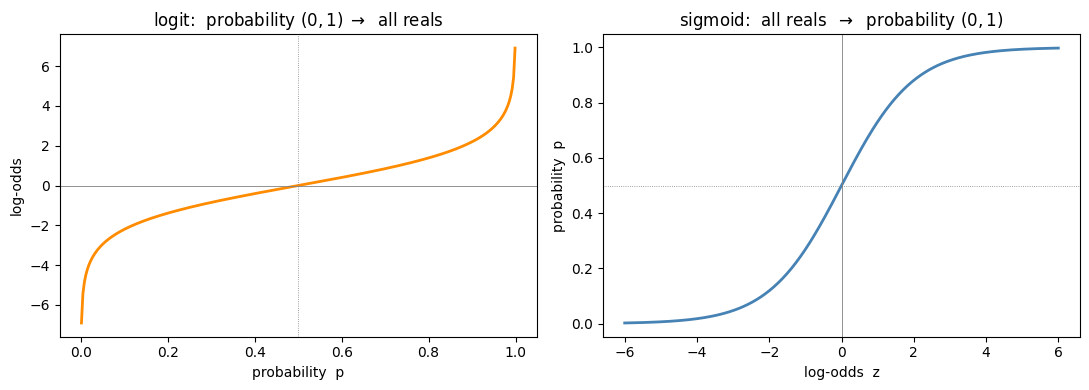

sigmoid(logit(0.8)) = 0.8

coefficient beta = 0.7  ->  odds ratio e^beta = 2.014
Reading: each one-unit rise in this predictor multiplies the odds by about 2.0x.


In [7]:
def logit(p):   return np.log(p / (1 - p))     # probability  -> log-odds
def sigmoid(z): return 1 / (1 + np.exp(-z))     # log-odds     -> probability

fig, axes = plt.subplots(1, 2, figsize=(11, 4))

p = np.linspace(0.001, 0.999, 300)
axes[0].plot(p, logit(p), color="darkorange", lw=2)
axes[0].axhline(0, color="grey", lw=0.6); axes[0].axvline(0.5, color="grey", lw=0.6, ls=":")
axes[0].set_title(r"logit:  probability $(0,1)\;\to\;$ all reals")
axes[0].set_xlabel("probability  p"); axes[0].set_ylabel("log-odds")

z = np.linspace(-6, 6, 300)
axes[1].plot(z, sigmoid(z), color="steelblue", lw=2)
axes[1].axhline(0.5, color="grey", lw=0.6, ls=":"); axes[1].axvline(0, color="grey", lw=0.6)
axes[1].set_title(r"sigmoid:  all reals $\;\to\;$ probability $(0,1)$")
axes[1].set_xlabel("log-odds  z"); axes[1].set_ylabel("probability  p")
plt.tight_layout(); plt.show()

# They are inverses:
print("sigmoid(logit(0.8)) =", round(sigmoid(logit(0.8)), 4))

# An odds ratio: a coefficient of 0.7 on the log-odds scale.
beta = 0.7
print(f"\ncoefficient beta = {beta}  ->  odds ratio e^beta =", round(np.exp(beta), 3))
print("Reading: each one-unit rise in this predictor multiplies the odds by about 2.0x.")

***
## R5.7 Bridge 2 — logs inside maximum likelihood estimation

The second destination. **Maximum likelihood** is the recipe behind the logistic fit (and much of Review 04): *pick the parameter value that makes the data we actually observed as probable as possible.*

**The product problem.** If observations are independent, the probability of the whole dataset is the **product** of the individual probabilities:

$$L(\text{parameter}) = p_1 \cdot p_2 \cdots p_n.$$

For any real dataset this is a product of hundreds of numbers each below 1 — vanishingly tiny, and awkward to compare.

**The log fixes it — using both of our properties.**
Take the log of the likelihood. By the **product → sum** rule (R5.4), the unwieldy product becomes a friendly **sum**:

$$\ln L = \ln p_1 + \ln p_2 + \dots + \ln p_n.$$

And by **monotonicity** (R5.5b), the parameter that maximises $\ln L$ is the **same** one that maximises $L$ — so we lose nothing by maximising the easy version. This is why you always see the **log-likelihood**, never the raw likelihood.

Let's watch it on the simplest possible case: a coin flipped **10 times, landing 7 heads**. The likelihood of a head-probability $p$ is $L(p) = p^{7}(1-p)^{3}$, and its log is $\ln L(p) = 7\ln p + 3\ln(1-p)$:

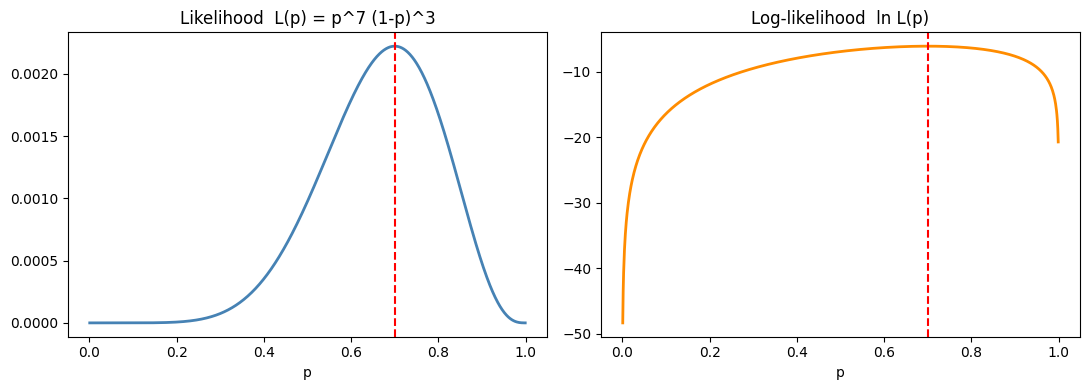

p that maximises L(p)     : 0.7
p that maximises ln L(p)  : 0.7
-> both peak at 0.70 = 7/10, the sample proportion. That is the maximum-likelihood estimate.


In [8]:
p = np.linspace(0.001, 0.999, 999)
L    = p**7 * (1 - p)**3                 # likelihood (a tiny product)
logL = 7*np.log(p) + 3*np.log(1 - p)     # log-likelihood (a friendly sum)

fig, axes = plt.subplots(1, 2, figsize=(11, 4))
axes[0].plot(p, L, color="steelblue", lw=2);    axes[0].axvline(0.7, color="red", ls="--")
axes[0].set_title("Likelihood  L(p) = p^7 (1-p)^3"); axes[0].set_xlabel("p")
axes[1].plot(p, logL, color="darkorange", lw=2); axes[1].axvline(0.7, color="red", ls="--")
axes[1].set_title("Log-likelihood  ln L(p)");      axes[1].set_xlabel("p")
plt.tight_layout(); plt.show()

print("p that maximises L(p)     :", round(p[np.argmax(L)], 3))
print("p that maximises ln L(p)  :", round(p[np.argmax(logL)], 3))
print("-> both peak at 0.70 = 7/10, the sample proportion. That is the maximum-likelihood estimate.")

**From the coin to logistic regression.** In logistic regression each observation is a yes/no (Bernoulli) outcome whose probability $p$ comes from the sigmoid of R5.6. Writing $y = 1$ for "yes" and $y = 0$ for "no", the log-likelihood of the whole dataset is

$$\ln L = \sum_{i} \Big[\, y_i \ln p_i + (1 - y_i)\ln(1 - p_i) \,\Big].$$

Unlike the coin, there is no tidy formula for the maximiser, so the computer searches for it numerically — but the **principle is identical**: find the coefficients that make the observed yes/no pattern most probable. And the **deviance** Session 05 reports (§5.12) is simply $-2 \ln L$ at that best fit — a logarithm again, which is why *lower deviance = better fit*.

That closes the loop: the same two functions that unbounded a probability in R5.6 are what make the fitting itself tractable here.

***
## Recap — and where this shows up

A compact toolkit, and every piece earns its place downstream:

- **Exponents** and their rules (R5.1); the **exponential $e^x$** — always positive, and $e^{a+b}=e^a e^b$ (R5.2).
- **Logarithms** as the **inverse** of $e^x$ (R5.3), and the rule that does the heavy lifting: **a log turns a product into a sum** (R5.4).
- **Range-shifting** — $\ln$ frees a probability from $(0,1)$ onto the whole line; $e^x$ brings it back (R5.5a).
- **Monotonicity** — logs never move the location of a maximum (R5.5b).

Where you will use it:

- **Session 05 (logistic regression):** the **logit** $\ln\frac{p}{1-p}$ (§5.5), the **sigmoid** (§5.6), **odds ratios** $e^{\beta}$ (§5.11).
- **Session 05 & Review 04 (maximum likelihood):** the **log-likelihood** as a sum of logs, and the **deviance** $-2\ln L$ (§5.8, §5.12).

*(One aside for the curious: logarithms turn up a third time in **Review 03**, where $\log_2$ measures information as entropy. Same function, a different base — a story for that notebook.)*

You now have everything the two destinations require — and, true to the plan, nothing they do not.

<hr>

![](../_img/DK_Logo_White_150.png)

DataKolektiv, 2026.

[hello@datakolektiv.com](mailto:hello@datakolektiv.com)

<font size=1>License: [GPLv3](../LICENSE). This Notebook is free software: you can redistribute it and/or modify it under the terms of the GNU General Public License as published by the Free Software Foundation, either version 3 of the License, or (at your option) any later version. This Notebook is distributed in the hope that it will be useful, but WITHOUT ANY WARRANTY; without even the implied warranty of MERCHANTABILITY or FITNESS FOR A PARTICULAR PURPOSE. See the GNU General Public License for more details.</font>